# prep

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset, Sampler
from torch.utils.tensorboard import SummaryWriter
import torch.optim as optim

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import zscore
import os, math, random

device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
from tensorboard import program

log_dir='runs.tb2'
tb = program.TensorBoard()
tb.configure(argv=[None, '--logdir', log_dir])
tb_url = tb.launch()
print(tb_url)

http://localhost:6006/


In [7]:
def _load(paths, mmap=True):
    # mmap=True avoids loading all 20 subjects' TFRs into RAM (torch>=2.1)
    return [torch.load(p, mmap=mmap) for p in paths]

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

class RandomSliceDataset(Dataset):
    """Random windows from raw/TFR for autoencoder training.
    `win` is in TFR frames; the raw window is win*decim samples, aligned to the TFR."""

    def __init__(self, paths, win=256, decim=4, n_samples=10_000, mmap=True):
        self.sessions = _load(paths, mmap)
        self.win, self.decim, self.n_samples = win, decim, n_samples
        # usable length in TFR frames (guard against off-by-one from decimation)
        lengths = [min(s['tfr'].shape[-1], s['raw'].shape[-1] // decim)
                   for s in self.sessions]
        self.n_starts = [L - win + 1 for L in lengths]
        # sample recordings proportionally to how many windows they offer
        self.w = torch.tensor(self.n_starts, dtype=torch.float)

    def __len__(self):
        return self.n_samples  # "virtual epoch"; idx is ignored

    def __getitem__(self, idx):
        k = torch.multinomial(self.w, 1).item()
        t0 = torch.randint(0, self.n_starts[k], (1,)).item()   # TFR frame
        r0 = t0 * self.decim                                   # raw sample
        s = self.sessions[k]
        return {
            'raw': s['raw'][:, r0:r0 + self.win * self.decim].float(),
            'tfr': s['tfr'][..., t0:t0 + self.win].float(),
        }

class VarLenSliceDataset(Dataset):
    """Index is the window length (TFR frames); every item in a batch gets the same one."""
    def __init__(self, paths, decim=4, mmap=True, pool=None, channels=slice(-1, None)):
        self.sessions = []
        for p in paths:
            s = torch.load(p, mmap=mmap)
            self.sessions.append({'raw': s['raw'][channels], 'tfr': s['tfr'][channels]})
        self.decim = decim
        self.pool = tuple(pool) if pool else None
        self.lengths = [min(s['tfr'].shape[-1], s['raw'].shape[-1] // decim)
                        for s in self.sessions]

    def __len__(self):
        return 10**9

    def __getitem__(self, win):
        w = torch.tensor([max(L - win + 1, 0) for L in self.lengths], dtype=torch.float)
        k = torch.multinomial(w, 1).item()
        t0 = torch.randint(0, int(w[k]), (1,)).item()
        r0 = t0 * self.decim
        s = self.sessions[k]
        tfr = s['tfr'][..., t0:t0 + win].float()
        if self.pool is not None and self.pool != (1, 1):
            tfr = F.avg_pool2d(tfr, self.pool, ceil_mode=True)
        return s['raw'][:, r0:r0 + win * self.decim].float(), tfr

class VarLenBatchSampler(Sampler):
    def __init__(self, n_batches, batch_size, min_win=64, max_win=1024, step=16):
        self.n_batches, self.bs = n_batches, batch_size
        self.min_win, self.max_win, self.step = min_win, max_win, step

    def __len__(self):
        return self.n_batches

    def __iter__(self):
        lo, hi = math.log(self.min_win), math.log(self.max_win)
        for _ in range(self.n_batches):
            win = int(round(math.exp(random.uniform(lo, hi)) / self.step)) * self.step
            yield [win] * self.bs   # the "indices" are the window length

class FixedWinBatchSampler(Sampler):
    """Deterministic list of window sizes for validation."""
    def __init__(self, wins=(64, 128, 256, 512, 1024), reps=4, batch_size=32):
        self.batches = [[w] * batch_size for w in wins for _ in range(reps)]
    def __len__(self):
        return len(self.batches)
    def __iter__(self):
        return iter(self.batches)

class EventDataset(Dataset):
    """One item per n-back event. Window ends at event + post and extends back a variable
    number of TFR frames in [min_pre, max_pre]. Units are TFR frames (raw samples = frames * decim)."""

    def __init__(self, paths, min_pre=64, max_pre=256, post=128, eval_pre=256,
                decim=4, train=True, mmap=True):
        self.sessions = _load(paths, mmap)
        self.post, self.decim, self.train = post, decim, train

        # hard width limits, in TFR frames
        self.min_width = min_pre
        self.max_width = max_pre + post
        self.eval_width = eval_pre + post
        assert self.min_width <= self.max_width, "min_pre must be <= max_pre + post"

        self.index = []  # (session_idx, event_frame, label)
        for k, s in enumerate(self.sessions):
            T = min(s['tfr'].shape[-1], s['raw'].shape[-1] // decim)
            for samp, lab in s['labels'].tolist():
                c = samp // decim
                # event must support the widest window: start = c + post - max_width >= 0
                if c + post - self.max_width >= 0 and c + post <= T:
                    self.index.append((k, c, lab))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        k, c, lab = self.index[i]
        width = random.randint(self.min_width, self.max_width) if self.train else self.eval_width
        b = c + self.post
        a = b - width
        raw = self.sessions[k]['raw'][:, a * self.decim:b * self.decim]
        return {'raw': raw, 'label': torch.tensor(lab, dtype=torch.long)}

def collate_variable(batch, pad_left=True):
    """Pads raw (C, T_i) to (B, C, T_max). Returns padding_mask (B, T_max), True = padded."""
    lengths = [b['raw'].shape[-1] for b in batch]
    T_max, C = max(lengths), batch[0]['raw'].shape[0]
    raw = torch.zeros(len(batch), C, T_max)
    mask = torch.ones(len(batch), T_max, dtype=torch.bool)
    for i, b in enumerate(batch):
        L = lengths[i]
        sl = slice(T_max - L, T_max) if pad_left else slice(0, L)
        raw[i, :, sl] = b['raw']
        mask[i, sl] = False
    labels = torch.stack([b['label'] for b in batch])
    return {'raw': raw, 'padding_mask': mask, 'label': labels}

In [5]:
#working components
    
def sinusoidal_pos(T, d, device):
    pos = torch.arange(T, device=device).unsqueeze(1)
    div = torch.exp(torch.arange(0, d, 2, device=device) * (-math.log(10000.0) / d))
    pe = torch.zeros(T, d, device=device)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

class SpatialAttention(nn.Module):
    """Per-timestep attention across electrodes."""
    def __init__(self, n_channels, d_k=16, dropout=0.1):
        super().__init__()
        self.q = nn.Linear(1, d_k)
        self.k = nn.Linear(1, d_k)
        self.ch_q = nn.Parameter(torch.randn(n_channels, d_k) * 0.02)
        self.ch_k = nn.Parameter(torch.randn(n_channels, d_k) * 0.02)
        self.drop = nn.Dropout(dropout)
        self.scale = d_k ** -0.5

    def forward(self, x):                      # x: (B, N, C)
        v = x.unsqueeze(-1)                    # (B, N, C, 1)
        q = self.q(v) + self.ch_q              # (B, N, C, d_k)
        k = self.k(v) + self.ch_k
        attn = (q @ k.transpose(-1, -2)) * self.scale   # (B, N, C, C)
        attn = self.drop(attn.softmax(-1))
        return x + (attn @ v).squeeze(-1)      # residual, (B, N, C)

class Head(nn.Module): #mlp output
    """
    (B, T', d_model) → (B, T', C * F)
    Two hidden layers + GELU, LayerNorm, and a linear residual skip
    so the MLP only has to learn the *correction*.
    """
    def __init__(self, d_model: int, out_dim: int, hidden: int | None = None,
                 dropout: float = 0.1):
        super().__init__()
        h = hidden or 2 * d_model
        self.norm = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, h),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h, h),
            nn.GELU(),
            nn.Dropout(dropout),
        )
        self.proj = nn.Linear(h, out_dim)
        self.skip = nn.Linear(d_model, out_dim)   # residual linear

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.mlp(self.norm(x))
        return self.proj(h) + self.skip(self.norm(x))

class RawToTFR(nn.Module):
    """
    EEG  (B, C, T_raw)  →  TFR  (B, C, F, T_raw // decim)

    decim = 4  with the default stem (two stride-2 convs).
    """
    def __init__(
        self,
        n_channels: int = 20,
        n_freqs: int = 120,
        d_model: int = 128,
        nhead: int = 8,
        num_layers: int = 4,
        dim_ff: int = 512,
        dropout: float = 0.1,
        decim: int = 4,          # 2 or 4; must match the stem
        use_spatial_attn: bool = True,
    ):
        super().__init__()
        self.C, self.F = n_channels, n_freqs
        self.decim = decim

        # ── optional raw-signal spatial mixer ──
        self.spatial_raw = (
            SpatialAttention(n_channels, d_k=32) if use_spatial_attn else None
        )

        # ── stem:  T_raw → T_raw // decim,  C → d_model ──
        if decim == 4:
            self.stem = nn.Sequential(
                nn.Conv1d(n_channels, d_model, kernel_size=7, stride=2, padding=3),
                nn.GELU(),
                nn.Conv1d(d_model, d_model, kernel_size=7, stride=2, padding=3),
                nn.GELU(),
            )
        elif decim == 2:
            self.stem = nn.Sequential(
                nn.Conv1d(n_channels, d_model, kernel_size=7, stride=2, padding=3),
                nn.GELU(),
            )
        else:
            raise ValueError(f"decim must be 2 or 4, got {decim}")

        # ── channel identity embedding (learnable) ──
        self.ch_emb = nn.Parameter(
            0.02 * torch.randn(n_channels, d_model)
        )
        # We'll add ch_emb[c] to the feature of channel c via a small
        # 1-D conv trick after the stem (see _add_channel_info below).

        self.norm_in = nn.LayerNorm(d_model)

        # ── transformer ──
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            norm_first=True,          # Pre-LN: more stable for deep stacks
        )
        self.encoder = nn.TransformerEncoder(
            enc_layer,
            num_layers=num_layers,
            enable_nested_tensor=False,   # ← important for variable T
            norm=nn.LayerNorm(d_model),
        )

        # ── head ──
        self.head = Head(
            d_model=d_model,
            out_dim=n_channels * n_freqs,
            hidden=2 * d_model,
            dropout=dropout,
        )

        self._init_weights()

    def _add_channel_info(self, z: torch.Tensor) -> torch.Tensor:
        """
        z: (B, T', d_model)  –  the transformer sees *time* tokens.
        We inject a channel-aware bias by running a 1-D conv over the
        channel axis *before* the stem, so d_model already carries
        channel identity.  Here we simply add a learned per-channel
        offset that was mixed in by the stem's first conv.
        (If you want an explicit additive channel code, swap the stem
         for a Conv2d(C, F, 1, 1) on a reshaped input.)
        """
        # Lightweight version: add the channel-mean of ch_emb as a global bias
        # (the per-channel structure is already in the stem's C → d_model conv).
        return z + self.ch_emb.mean(0).unsqueeze(0).unsqueeze(0)  # (1, 1, d)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def encode(self, x, padding_mask=None):          # (B, C, T_raw) -> (B, T', d_model)
        if self.spatial_raw is not None:
            x = self.spatial_raw(x.transpose(1, 2)).transpose(1, 2)

        z = self.stem(x).transpose(1, 2)
        z = self.norm_in(z)
        z = z + sinusoidal_pos(z.size(1), z.size(2), z.device)
        z = z + self._add_channel_info(z)

        src_mask = None
        if padding_mask is not None:
            idx = (torch.arange(z.size(1), device=x.device) * self.decim)
            idx = idx.clamp(max=padding_mask.shape[1] - 1)
            src_mask = padding_mask[:, idx]

        return self.encoder(z, src_key_padding_mask=src_mask)

    def forward(self, x, padding_mask=None):
        z = self.encode(x, padding_mask)
        out = self.head(z)
        B, T_out, _ = out.shape
        return out.view(B, T_out, self.C, self.F).permute(0, 2, 3, 1)

In [ ]:
class ModelTrainer():
    def __init__(self,net:nn.Module,
                 trainloader:DataLoader,
                 valloader:DataLoader,
                 criterion,
                 optimizer=optim.AdamW,
                 name=None,base='runs', 
                 max_epochs=100, 
                 patience=None,
                 delta=0.05,
                 device=None, 
                 val_schedular:optim.lr_scheduler.LRScheduler=None,
                 epoch_schedular:optim.lr_scheduler.LRScheduler=None,
                 iter_schedular:optim.lr_scheduler.LRScheduler=None,
                 l1=0,
                 l2=0,
                 x_idx=0,
                 y_idx=1,
                 mask_idx=None
                 ):
        
        #writer vars
        if name is None:
            raise ValueError('Model name not provided')
        self.base=base
        self.name=name
        self.fpath=f'{self.base}/{self.name}'
        self.writer=None

        #net vars
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.net=net.to(self.device)
        for p in self.net.parameters(): #check for bad parameters firs
            if not torch.isfinite(p).all():
                print("Model parameters contain inf/NaN")
                self.should_break=True

        #data args
        self.trainloader=trainloader
        self.valloader=valloader
        self.val_len=len(self.valloader)

        #early stopping vars
        self.patience=patience
        self.delta=delta
        self.best_model=self.net.state_dict()
        self.best_score=None

        #training vars
        self.max_epochs=max_epochs
        self.criterion=criterion.to(self.device)
        self.optimizer=optimizer
        self.val_schedular= val_schedular
        self.epoch_schedular = epoch_schedular
        self.iter_schedular=iter_schedular
        self.iter=0
        self.epoch=0
        self.l1=l1
        self.l2=l2
        self.x_idx=x_idx
        self.y_idx=y_idx
        self.mask_idx=mask_idx

        #utility args
        self.should_break=False

    def write_params(self):
        for tag, value in self.net.named_parameters():
            if torch.isnan(value).any():
                print('error writing histogram, model parameters contain nan')
                return
            tag = tag.replace('.', '/')
            self.writer.add_histogram(tag, value.data,global_step=self.epoch)
            if value.grad is not None:
                self.writer.add_histogram(tag+'/grad', value.grad.data,global_step=self.epoch)

    def graph_network(self, sample=None):
        self.net.eval()
        dataloader=DataLoader(self.dataset,batch_size=10,shuffle=False, collate_fn=self.collate_fn)
        writer=SummaryWriter(log_dir=f'{self.fpath}/graph')
        with torch.no_grad():
            x,y,mask = next(iter(dataloader))
            writer.add_graph(self.net, x.to(self.device),use_strict_trace=False)
        writer.close()

    def _l1(self):
        l1_norm = torch.tensor(0)
        for name, param in self.net.named_parameters():
            if not (param.requires_grad and 'weight' in name and 'bn' not in name.lower()):
                continue
            l1_norm += param.abs().sum()
        return self.l1 * l1_norm

    def _l2(self):
        l2_norm = torch.tensor(0)
        for name, param in self.net.named_parameters():
            if not (param.requires_grad and 'weight' in name and 'bn' not in name.lower()):
                continue
            l2_norm += param.pow(2).sum()
        return self.l2 * l2_norm

    def _iter(self, batch):
        data=batch[self.x_idx].to(self.device)
        labels=batch[self.y_idx].to(self.device)
        if self.mask_idx is not None:
            mask_batch=batch[self.mask_idx].to(self.device)
            output = self.net(data, mask_batch)
        else:
            output=self.net(data)
        
        loss = self.criterion(output, labels) #base loss
        l1_loss=self._l1() if self.l1>0 else torch.tensor(0) #may have to move to device
        l2_loss=self._l2() if self.l2>0 else torch.tensor(0)

        #write loss
        self.writer.add_scalar('Loss/L1',l1_loss,self.iter)
        self.writer.add_scalar('Loss/L2',l2_loss,self.iter)
        self.writer.add_scalar('Loss/Base',loss,self.iter)
        loss+=(l1_loss+l2_loss)
        self.writer.add_scalar('Loss/Train',loss,self.iter)

        #update model params
        self.optimizer.zero_grad()
        loss.backward()

        #torch.nn.utils.clip_grad_norm_(self.net.parameters(), max_norm=1.0)
        self.optimizer.step()# Update the model parameters

        if self.iter_schedular:
            self.iter_schedular.step()
        self.iter+=1

    def _epoch(self):
        self.net.train()
        for batch in self.trainloader:
            if not self.should_break:
                self._iter(batch)
        self.epoch+=1
        if not self.should_break:
            try:
                self.write_params()
            except Exception as e:
                print(e)
                
    def _evaluate(self):
        self.net.eval()
        with torch.no_grad():
            vloss=0 #may need to move to device
            for batch in self.valloader:
                data=batch[self.x_idx].to(self.device)
                labels=batch[self.y_idx].to(self.device)
                if self.mask_idx is not None:
                    mask_batch=batch[self.mask_idx].to(self.device)
                    output = self.net(data, mask_batch)
                else:
                    output=self.net(data)
                    
                # Compute the loss  
                batch_loss = self.criterion(output, labels)
                if torch.isnan(batch_loss) or torch.isinf(batch_loss):
                    print(f'evaluation computed bad vloss = {batch_loss}')
                    continue 
                vloss += batch_loss  
            vloss/=self.val_len #average 
            if self.best_score is None:
                self.best_score=vloss
            elif vloss<self.best_score:
                self.best_score=vloss
                self.best_model=self.net.state_dict()
            self.writer.add_scalar('Loss/Eval',vloss,self.iter)
        return vloss
       
    def train(self):
        #reinit vars
        self.iter=0
        self.epoch=0
        self.should_break=False

        #setup tb writer
        print('setting up tb writer')
        if os.path.exists(self.fpath): #double check this
            runs = np.array([int(f) for f in os.listdir(self.fpath) if f.lstrip('-').isdigit()])
            if len(runs)==0:
                next_run=1
            else: next_run=runs.max()+1
            run=self.fpath+f'/{next_run}'
        else:
            run=self.fpath+f'/{0}'
        self.writer=SummaryWriter(log_dir=run)

        print('begining training loop')
        while True:
            if self.should_break: break
            self._epoch()
            if self.epoch_schedular:
                self.epoch_schedular.step()
            if self.should_break: break
            eval_loss=self._evaluate()
            if self.val_schedular and eval_loss:
                self.val_schedular.step(eval_loss)
            self.writer.add_scalar('LearningRate', self.optimizer.param_groups[0]['lr'], self.epoch)

            if self.epoch>self.max_epochs: self.should_break=True
        print('training complete')

    def save_model(self,fpath):        
        torch.save(self.best_model, fpath)

# Working tfr encoder training

In [ ]:
#working loop
# ---- split by recording: 1 test, ~15% val, rest train ----
paths = sorted('data/' + d for d in os.listdir('data'))
random.Random(0).shuffle(paths)
f_pool_len=3
test_paths = paths[:1]
n_val = max(1, round(0.15 * len(paths)))
val_paths = paths[1:1 + n_val]
train_paths = paths[1 + n_val:]
print(f"{len(train_paths)} train / {len(val_paths)} val / {len(test_paths)} test recordings")
print("test file:", test_paths[0])
ch = slice(0,21)                                   # CHANGED
eeg_train = VarLenSliceDataset(train_paths, pool=(f_pool_len, 1), channels=ch)
eeg_val   = VarLenSliceDataset(val_paths,   pool=(f_pool_len, 1), channels=ch)
eeg_test  = VarLenSliceDataset(test_paths,  pool=(f_pool_len, 1), channels=ch)

trainloader = DataLoader(eeg_train,
                        batch_sampler=VarLenBatchSampler(n_batches=2000, batch_size=64),
                        num_workers=0)
valloader  = DataLoader(eeg_val, batch_sampler=FixedWinBatchSampler(), num_workers=0)
# one file gives a noisy estimate, so use more windows per size
testloader = DataLoader(eeg_test, batch_sampler=FixedWinBatchSampler(reps=16), num_workers=0)
# ---- model / optimizer (unchanged) ----
tfr_encoder = RawToTFR(n_channels=20, n_freqs=120 // f_pool_len, use_spatial_attn=False,
                    d_model=128, dropout=0.5, dim_ff=512, num_layers=2).to(device) #changed to 1 channel to minimize number of parameters
print('nparams:', count_parameters(tfr_encoder))

params = [
    {"params": [p for n, p in tfr_encoder.named_parameters()
                if "head" not in n and "spatial" not in n], "weight_decay": 0.01},
    {"params": [p for n, p in tfr_encoder.named_parameters()
                if "head" in n or "spatial" in n], "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(params, lr=1e-3, betas=(0.9, 0.95))
schedular = torch.optim.lr_scheduler.StepLR(optimizer, gamma=0.2, step_size=800)
scaler = torch.amp.GradScaler('cuda')

@torch.no_grad()
def evaluate(model, loader):
    model.eval()                                   # turns off dropout (p=0.5 here)
    total, n = 0.0, 0
    with torch.random.fork_rng(devices=[]):        # fixed windows, training RNG untouched
        torch.manual_seed(0)
        for raw, tfr in loader:
            raw, tfr = raw.to(device), tfr.to(device)
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(raw)
            total += F.mse_loss(out.float(), tfr).item() * raw.shape[0]
            n += raw.shape[0]
    model.train()
    return total / n

# ---- training loop ----
losses, lr, val_losses = [], [], []        # val_losses holds (step, loss)
eval_every = 200
best_val, best_state, step = float('inf'), None, 0

tfr_encoder.train()
nepochs = 1
for epoch in range(nepochs):
    print(f"Epoch {epoch+1}/{nepochs}")
    for batch in trainloader:
        raw = batch[0].to(device, non_blocking=True)
        tfr = batch[1].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast('cuda', dtype=torch.float16):
            output = tfr_encoder(raw)
        loss = F.mse_loss(output.float(), tfr)     # loss in fp32

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        losses.append(loss.item())
        schedular.step()
        lr.append(schedular.get_last_lr())
        step += 1

        if step % eval_every == 0:
            v = evaluate(tfr_encoder, valloader)
            val_losses.append((step, v))
            if v < best_val:
                best_val = v
                best_state = {k: t.detach().cpu().clone() for k, t in tfr_encoder.state_dict().items()}
            print(f"step {step}: train {sum(losses[-eval_every:])/eval_every:.4f} | val {v:.4f} | best {best_val:.4f}")

# after the training loop:
v = evaluate(tfr_encoder, valloader); val_losses.append((step, v))
if v < best_val:                                                   # CHANGED: final eval can be best too
    best_val = v
    best_state = {k: t.detach().cpu().clone() for k, t in tfr_encoder.state_dict().items()}

tfr_encoder.load_state_dict(best_state)
test_loss = evaluate(tfr_encoder, testloader)
print(f"best val {best_val:.4f} | test {test_loss:.4f}")

torch.save({                                                       # NEW
        'state_dict': best_state,
        'config': dict(n_channels=20, n_freqs=120 // f_pool_len, use_spatial_attn=False,
                       d_model=128, dropout=0.5, dim_ff=512, num_layers=2),
        'f_pool_len': f_pool_len,
        'best_val': best_val,
        'test_loss': test_loss,
        'losses': losses,
        'val_losses': val_losses,
    }, f'checkpoints/tfr_encoder_combined.pt')



14 train / 3 val / 1 test recordings
test file: data/processed_data_3.pt
nparams: 940352
Epoch 1/1
step 200: train 0.9156 | val 0.8234 | best 0.8234
step 400: train 0.8239 | val 0.7743 | best 0.7743
step 600: train 0.7841 | val 0.7530 | best 0.7530
step 800: train 0.7687 | val 0.7546 | best 0.7530
step 1000: train 0.7459 | val 0.7500 | best 0.7500
step 1200: train 0.7400 | val 0.7374 | best 0.7374
step 1400: train 0.7370 | val 0.7460 | best 0.7374
step 1600: train 0.7308 | val 0.7385 | best 0.7374
step 1800: train 0.7270 | val 0.7396 | best 0.7374
step 2000: train 0.7274 | val 0.7394 | best 0.7374
best val 0.7374 | test 0.7773


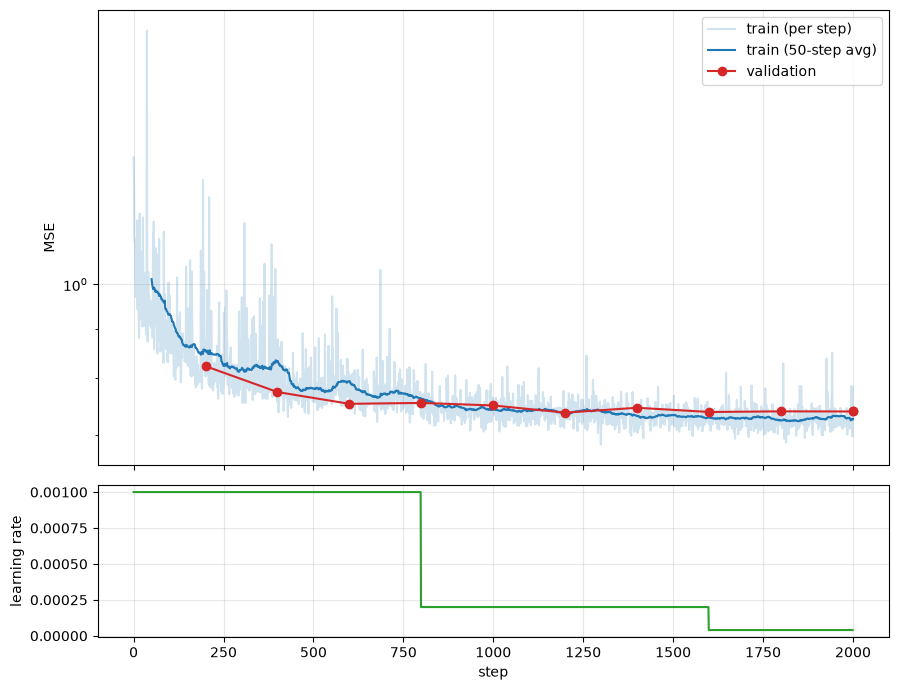

In [ ]:
#plot loss
def smooth(x, k=50):
    x = np.asarray(x, dtype=float)
    if len(x) < k:
        return x
    return np.convolve(x, np.ones(k) / k, mode='valid')

k = 50
train = np.asarray(losses)
sm = smooth(train, k)
steps_sm = np.arange(len(sm)) + k   # a window ending at step i covers k steps

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(train, alpha=0.2, color='C0', label='train (per step)')
ax1.plot(steps_sm, sm, color='C0', label=f'train ({k}-step avg)')
if val_losses:
    vs, vl = zip(*val_losses)
    ax1.plot(vs, vl, 'o-', color='C3', label='validation')
ax1.set_ylabel('MSE')
ax1.set_yscale('log')          # remove if you prefer a linear axis
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot([l[0] for l in lr], color='C2')
ax2.set_ylabel('learning rate')
ax2.set_xlabel('step')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

torch.Size([32, 20, 40, 64]) torch.Size([32, 20, 40, 64]) 0.7699074149131775


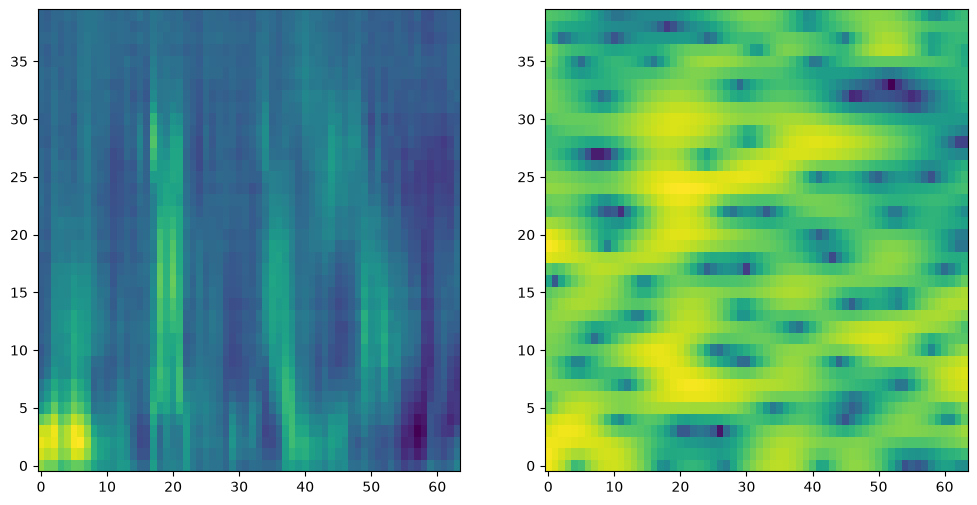

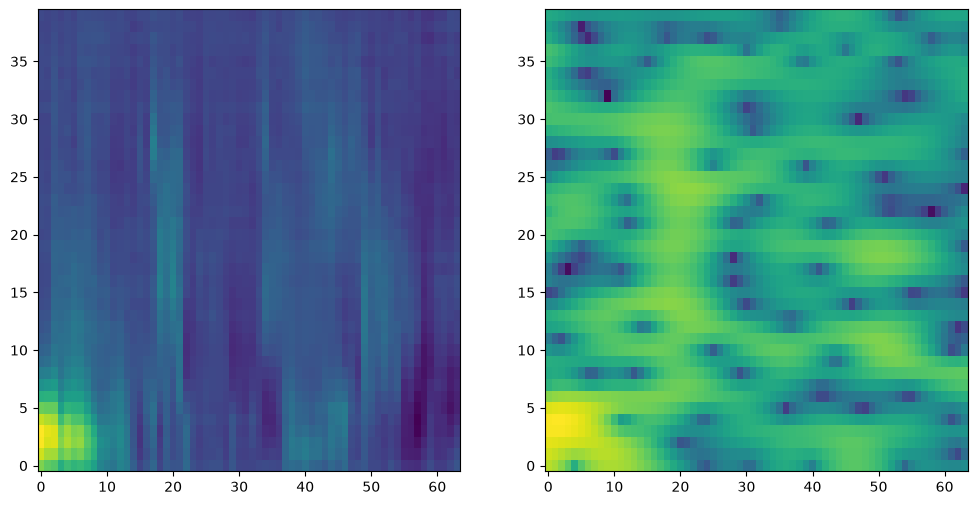

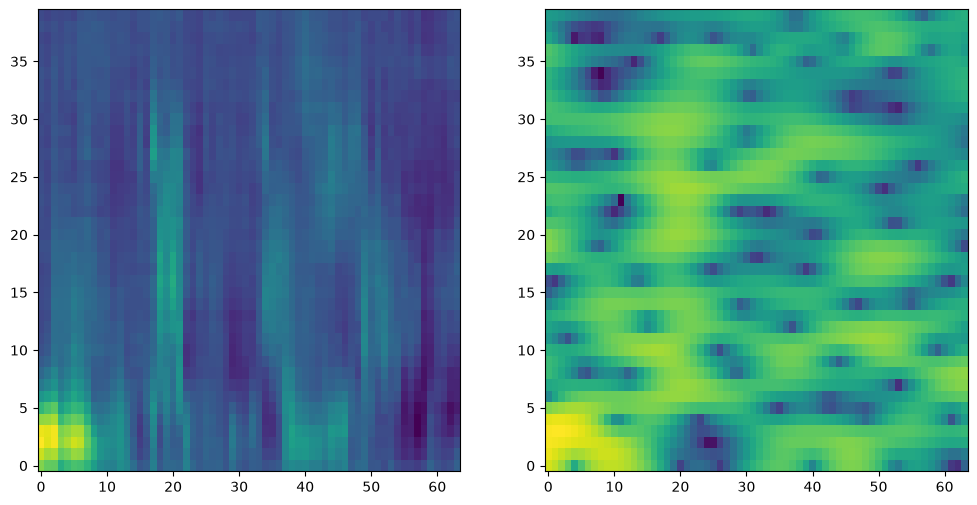

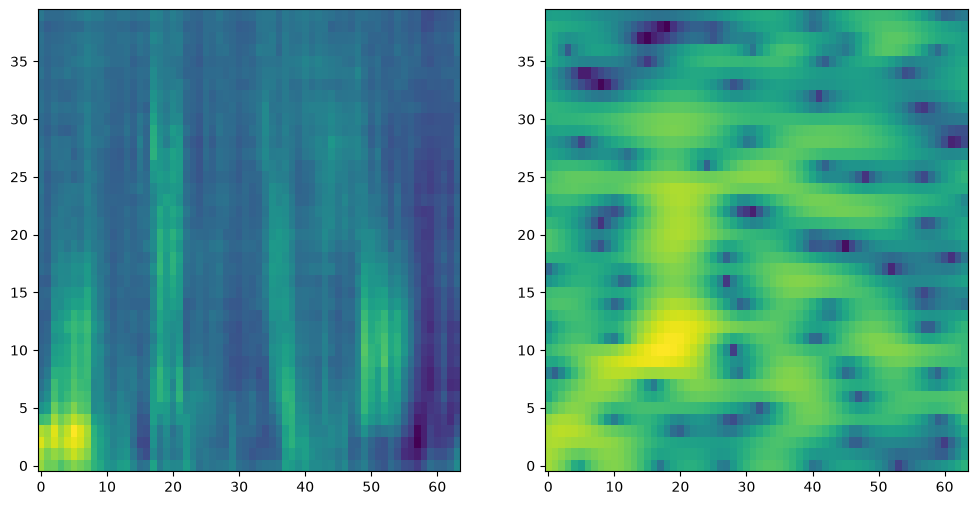

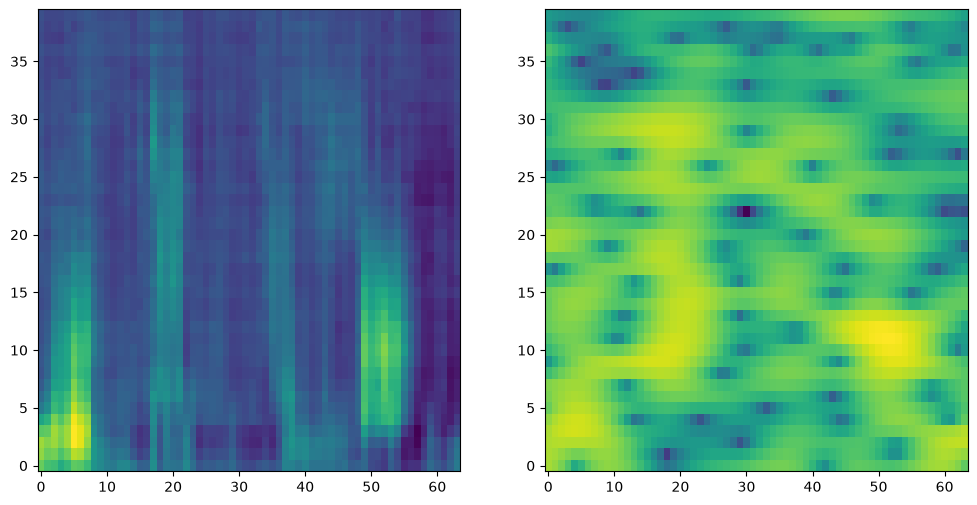

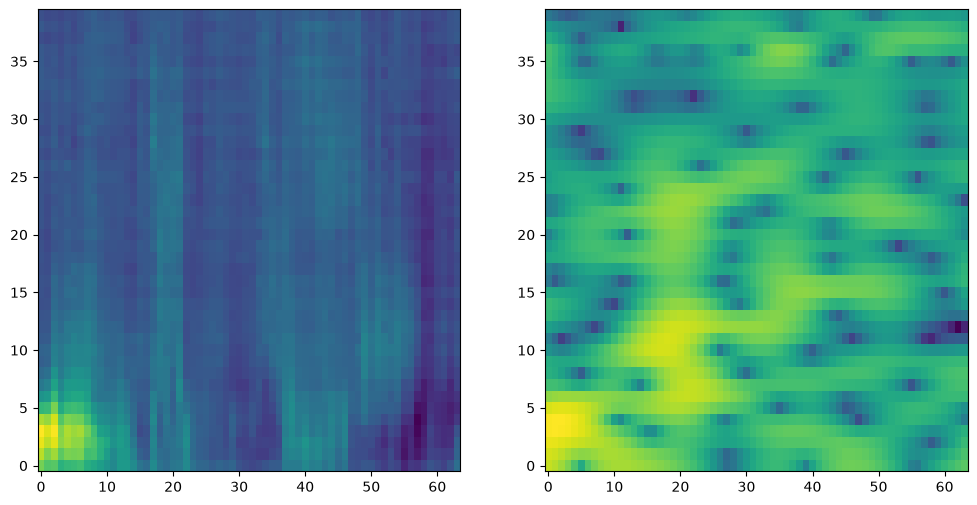

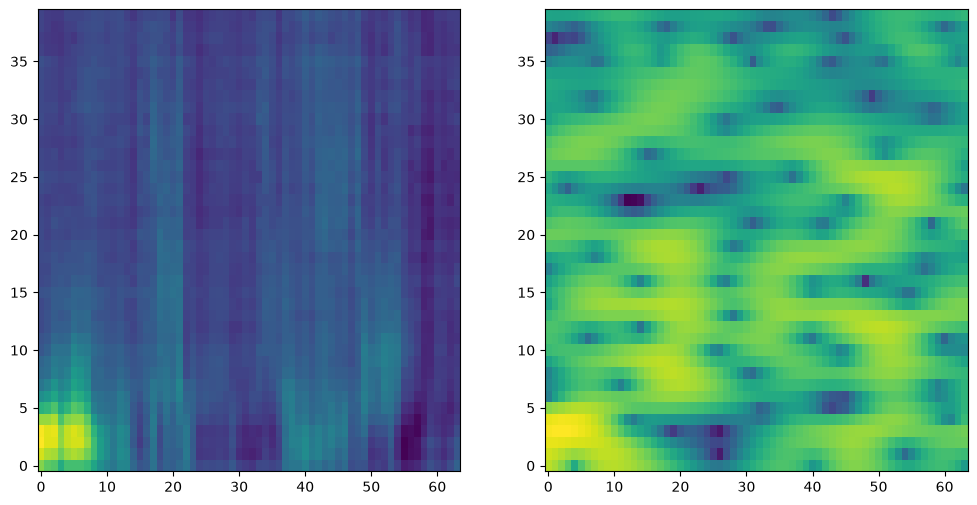

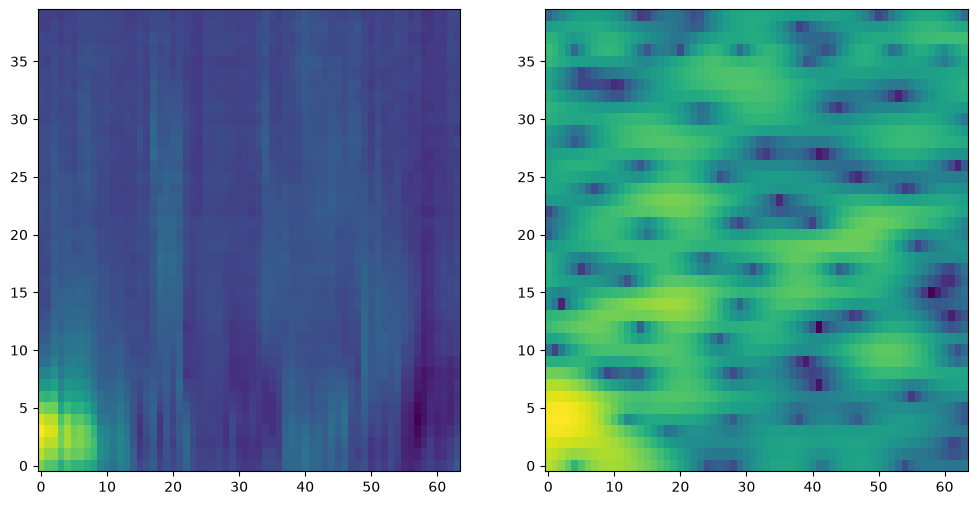

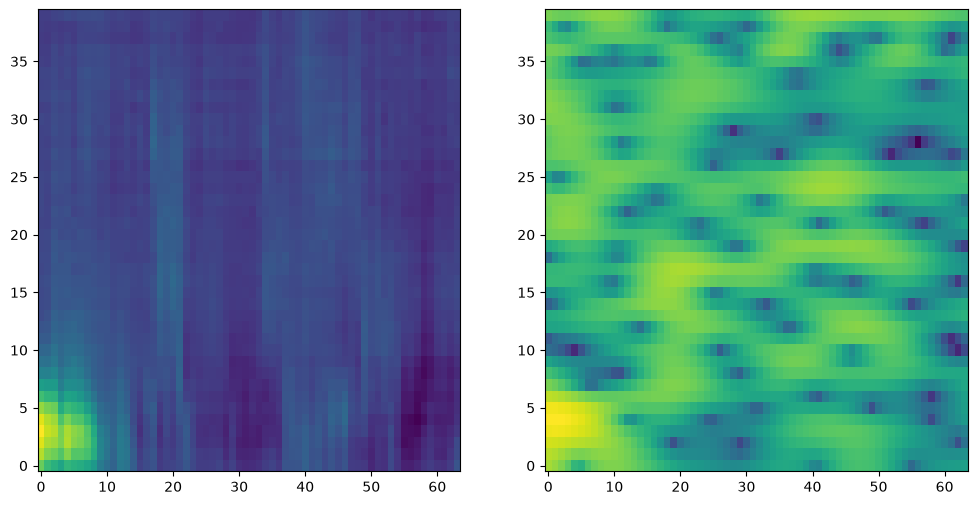

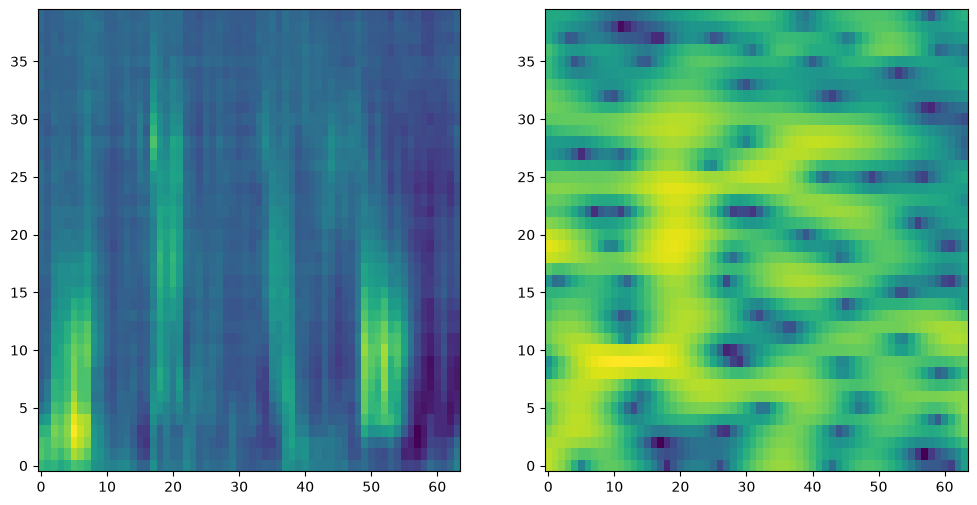

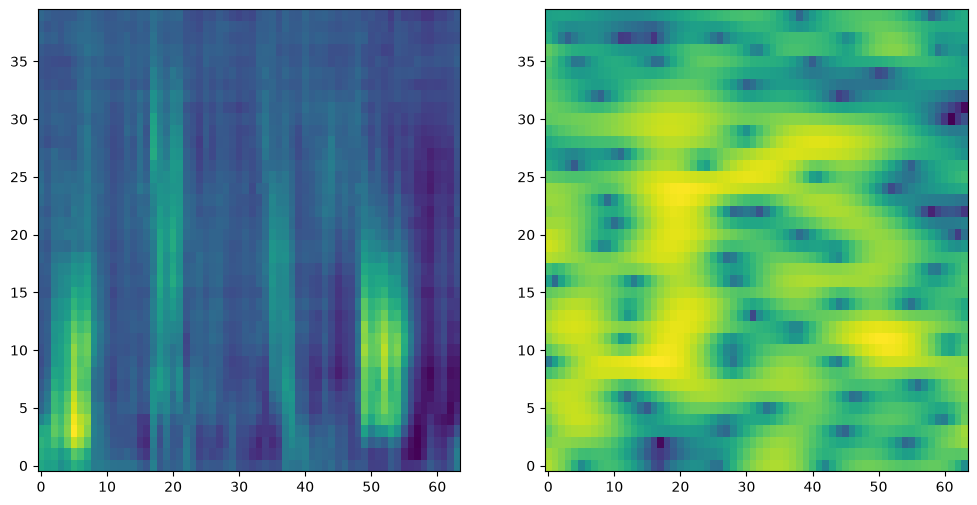

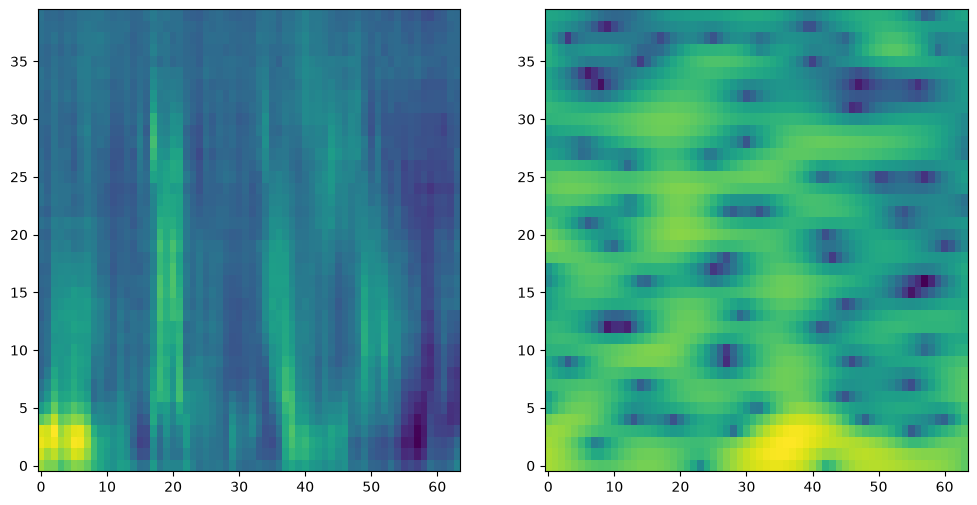

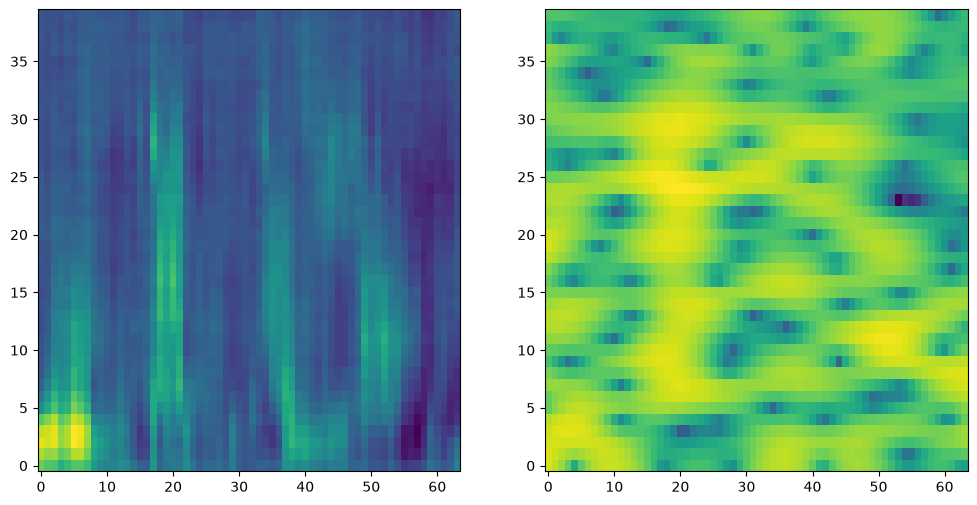

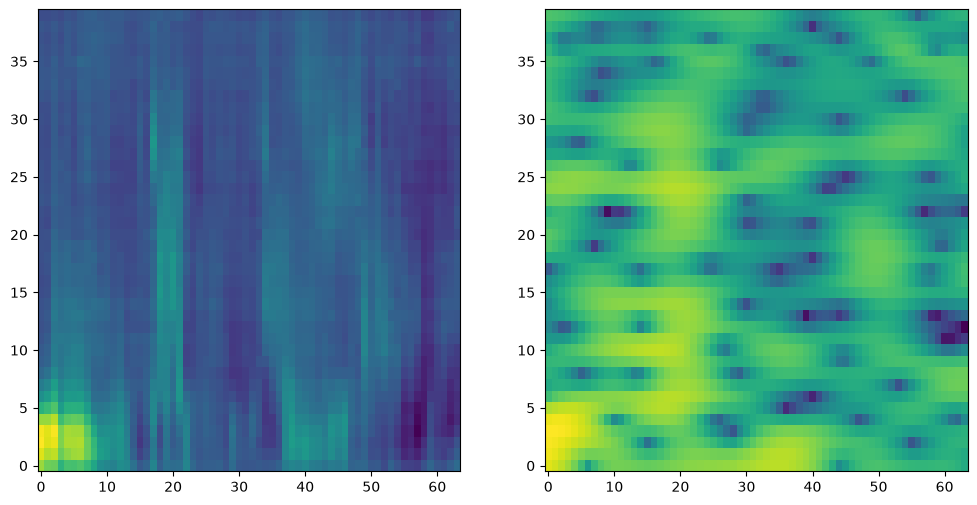

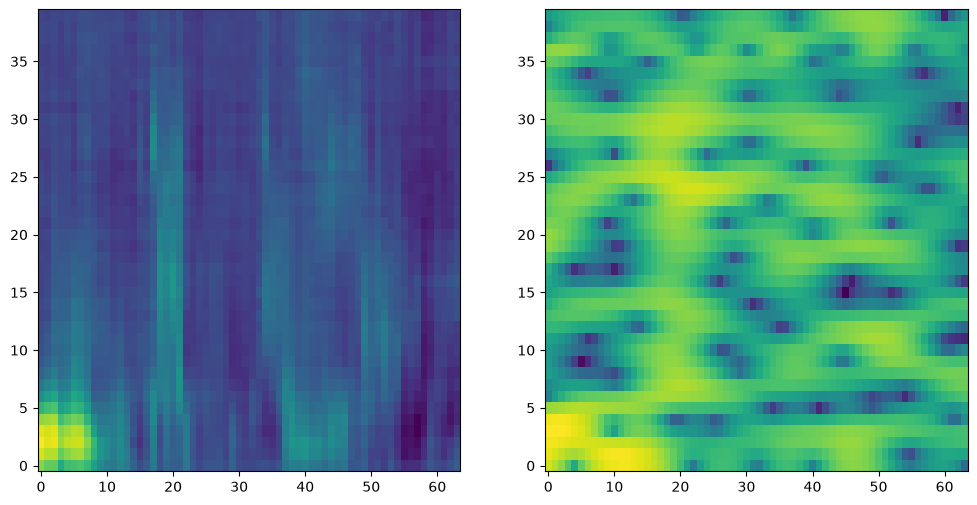

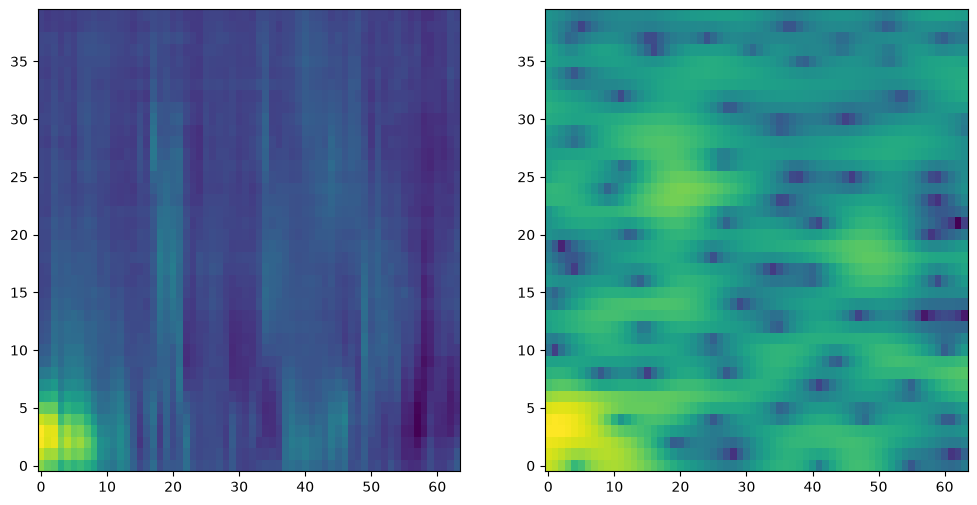

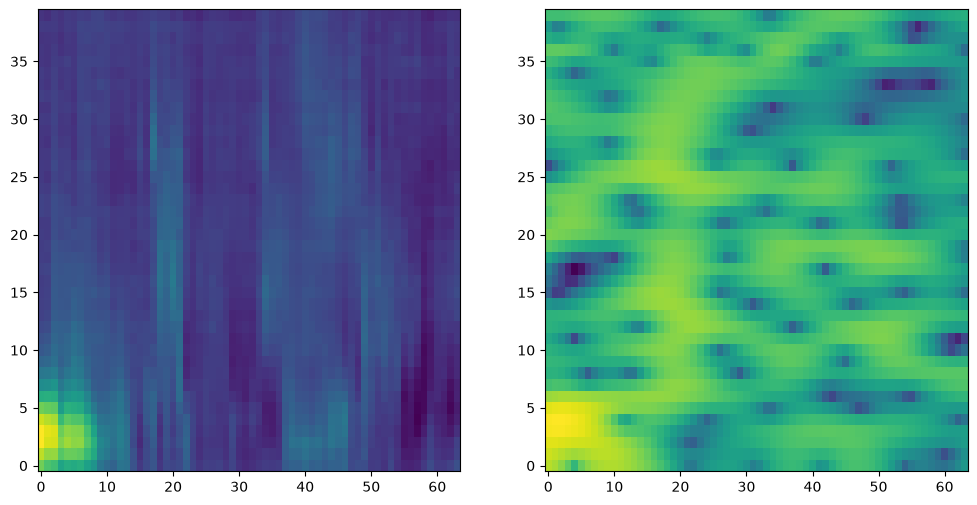

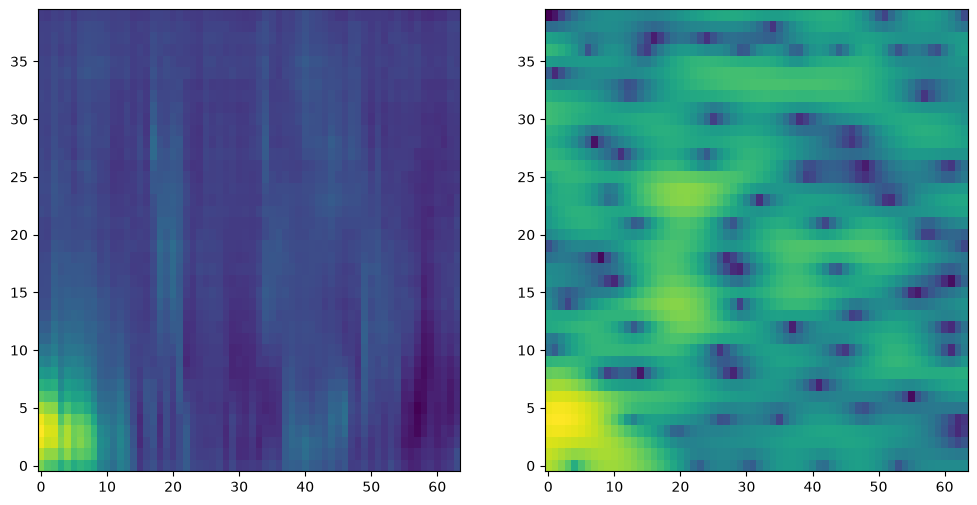

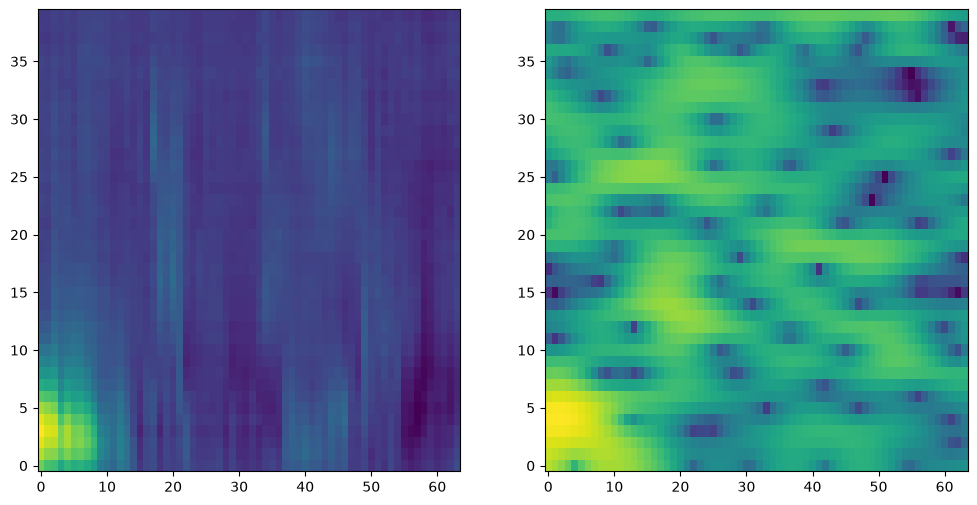

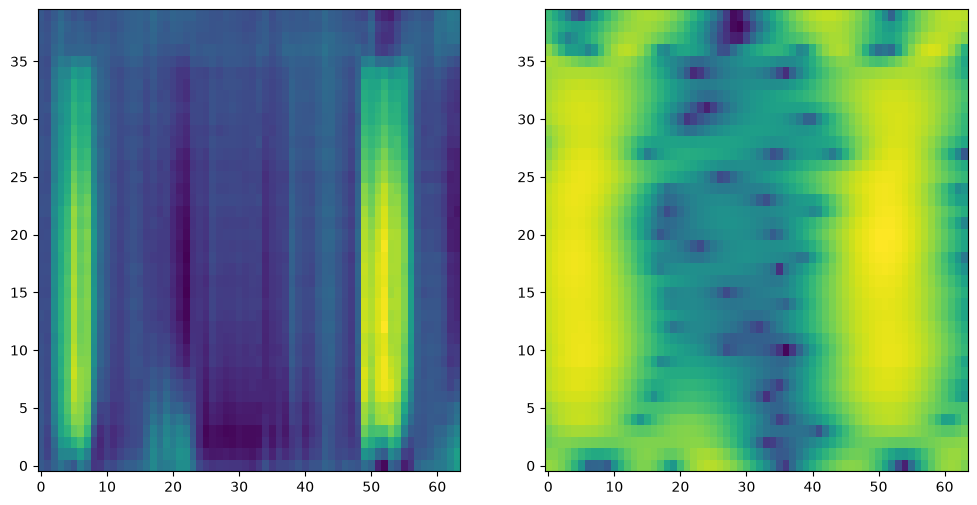

In [ ]:
#plot test images
tfr_encoder.eval()
with torch.no_grad():
    batch = next(iter(testloader))
    raw = batch[0].to(device)
    tfr = batch[1].to(device)
    with torch.autocast('cuda', dtype=torch.float16):   # matches how it was trained/evaluated
        output = tfr_encoder(raw).float()
    print(output.shape, tfr.shape, F.mse_loss(output, tfr).item())
    for sample, spectrogram in zip(output[0],tfr[0]): #each plot is channel
        fig, axs=plt.subplots(1,2,figsize=[12,6])
        axs[0].imshow(sample.cpu(),aspect='auto')
        axs[0].invert_yaxis()
        axs[1].imshow(spectrogram.cpu(),aspect='auto')
        axs[1].invert_yaxis()
        plt.show()

In [26]:
# use trainer class
paths = sorted('data/' + d for d in os.listdir('data'))
random.Random(0).shuffle(paths)
f_pool_len=3
test_paths = paths[:1]
n_val = max(1, round(0.15 * len(paths)))
val_paths = paths[1:1 + n_val]
train_paths = paths[1 + n_val:]
print(f"{len(train_paths)} train / {len(val_paths)} val / {len(test_paths)} test recordings")
print("test file:", test_paths[0])
ch = slice(0,21)                                   # CHANGED
eeg_train = VarLenSliceDataset(train_paths, pool=(f_pool_len, 1), channels=ch)
eeg_val   = VarLenSliceDataset(val_paths,   pool=(f_pool_len, 1), channels=ch)
eeg_test  = VarLenSliceDataset(test_paths,  pool=(f_pool_len, 1), channels=ch)

trainloader = DataLoader(eeg_train,
                        batch_sampler=VarLenBatchSampler(n_batches=2000, batch_size=64*2),
                        num_workers=0)
valloader  = DataLoader(eeg_val, batch_sampler=FixedWinBatchSampler(), num_workers=0)
testloader = DataLoader(eeg_test, batch_sampler=FixedWinBatchSampler(reps=16), num_workers=0)
model = RawToTFR(n_channels=20, n_freqs=120 // f_pool_len, use_spatial_attn=False,
                    d_model=128, dropout=0.5, dim_ff=512, num_layers=2).to(device) #changed to 1 channel to minimize number of parameters
print('nparams:', count_parameters(model))

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.95))
schedular = torch.optim.lr_scheduler.StepLR(optimizer, gamma=0.2, step_size=800)
#scaler = torch.amp.GradScaler('cuda')
loss_fn =nn.MSELoss()

trainer=ModelTrainer(model,trainloader,valloader,loss_fn,optimizer,'testloop',base=log_dir,max_epochs=100,iter_schedular=schedular)
trainer.train()

14 train / 3 val / 1 test recordings
test file: data/processed_data_3.pt
nparams: 940352
setting up tb writer
begining training loop


KeyboardInterrupt: 

torch.Size([128, 20, 40, 64]) torch.Size([128, 20, 40, 64]) 0.734180212020874


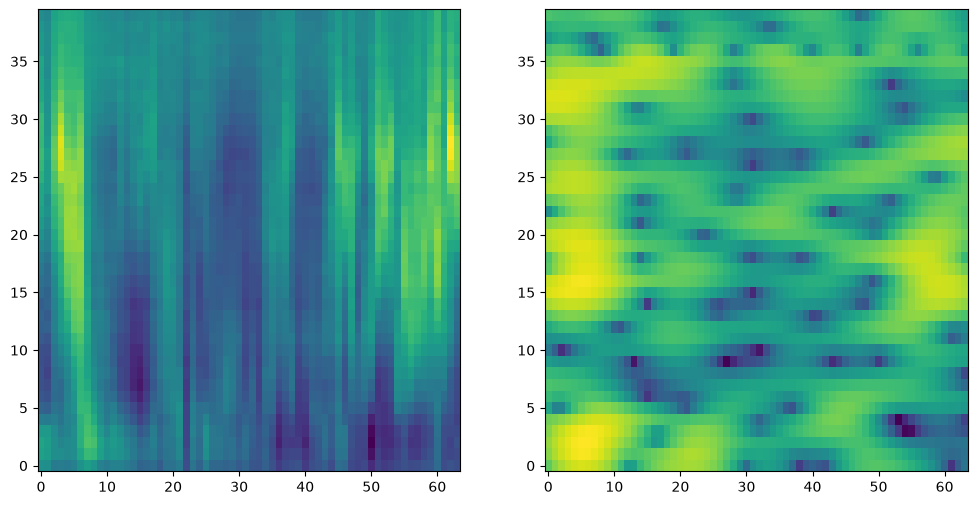

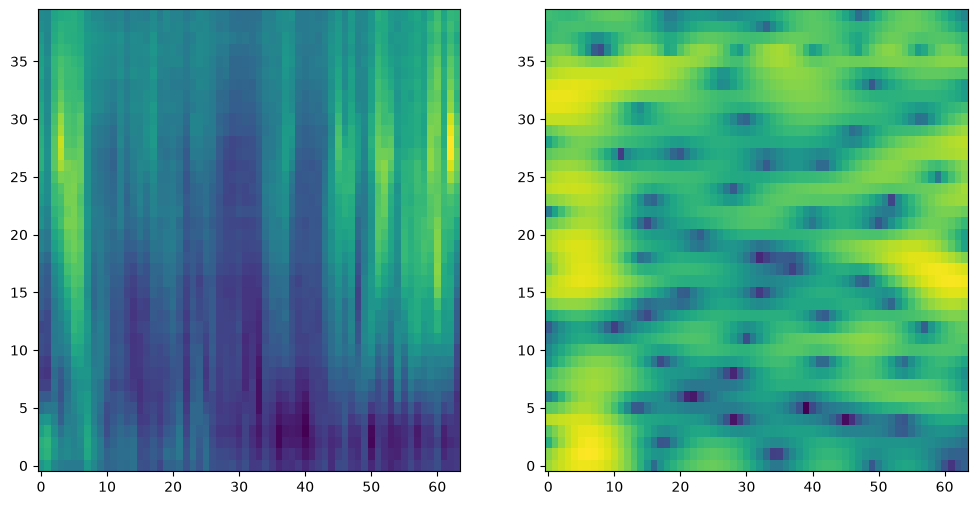

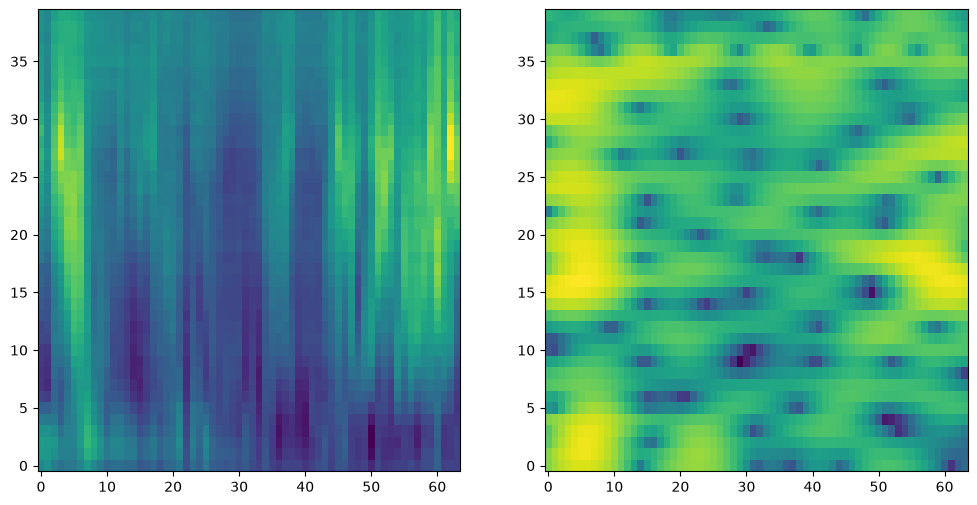

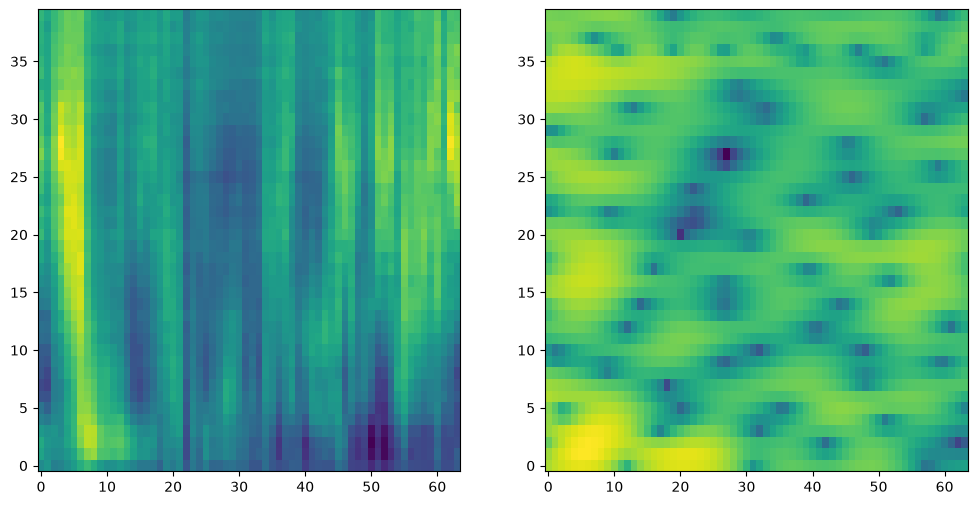

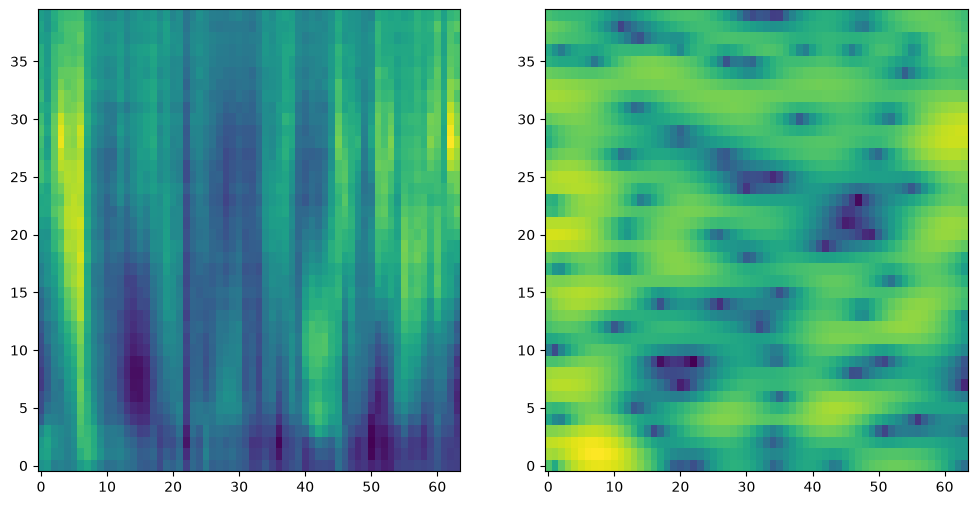

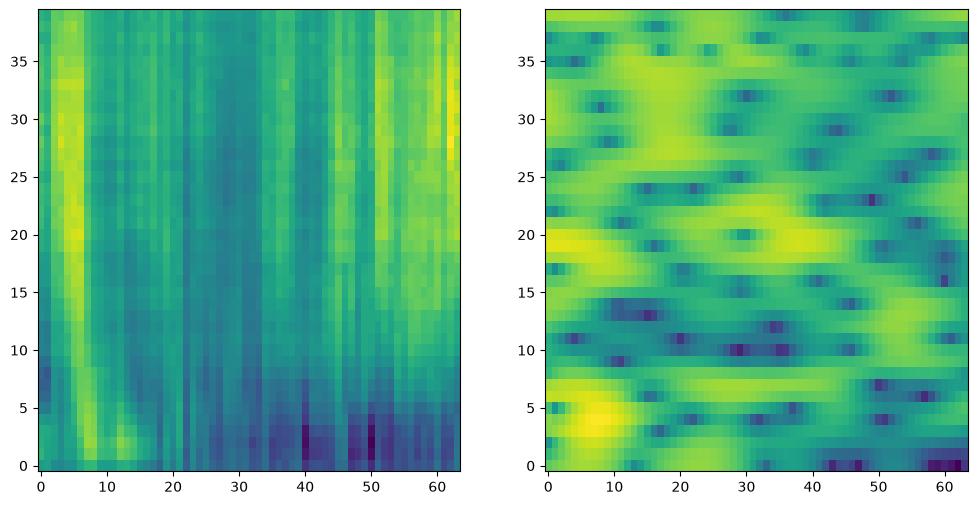

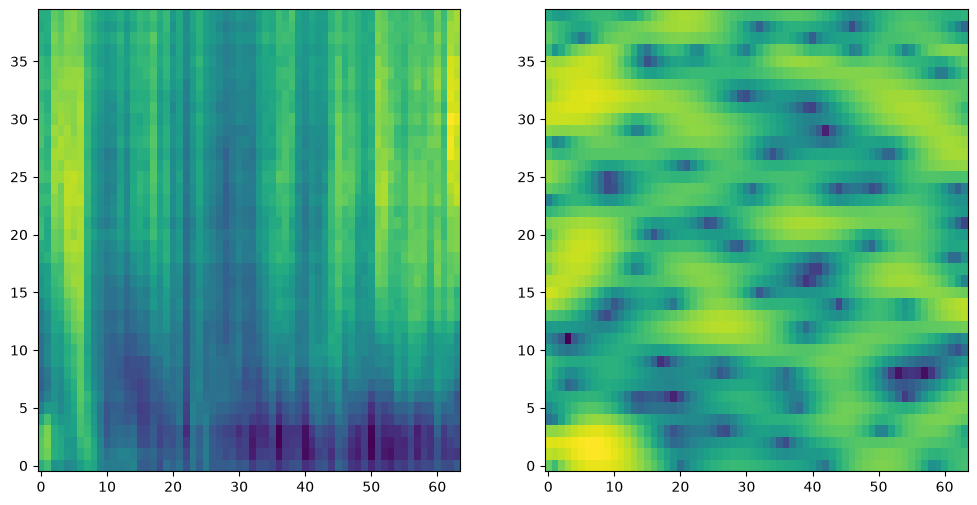

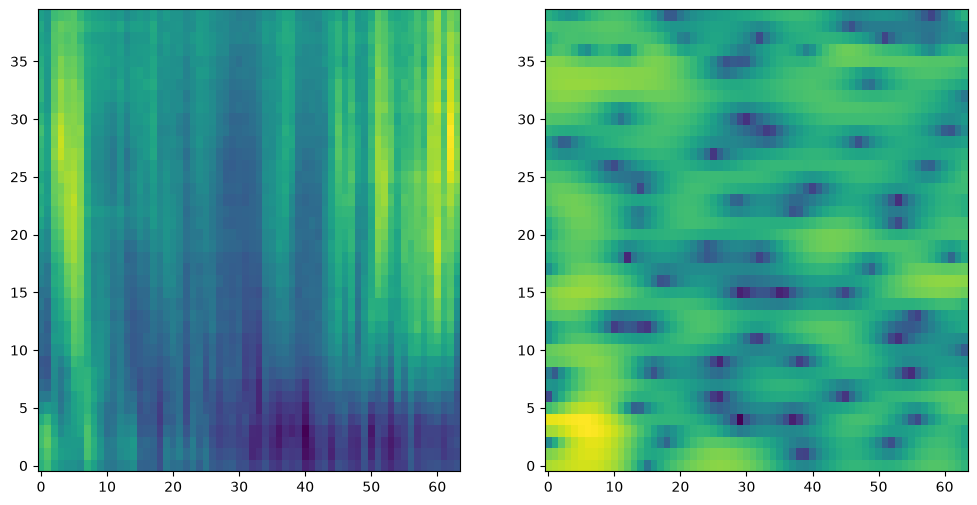

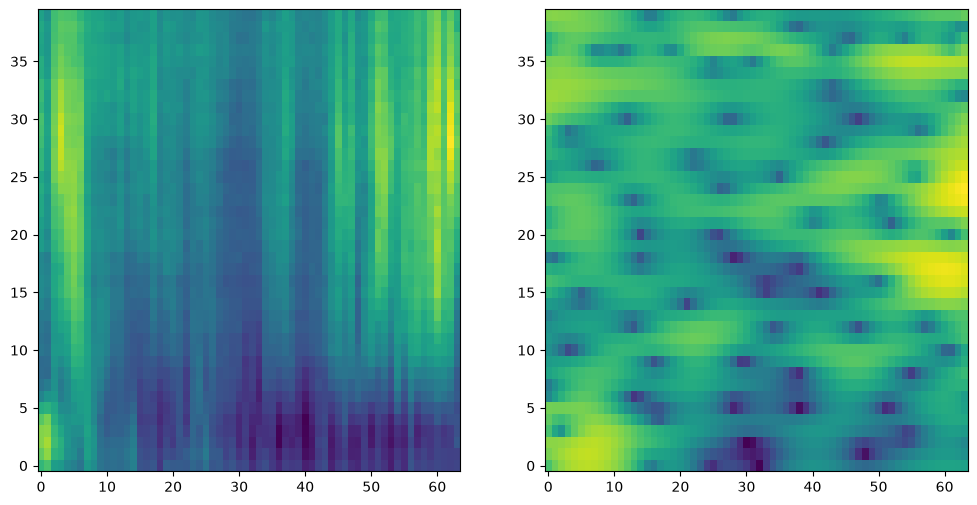

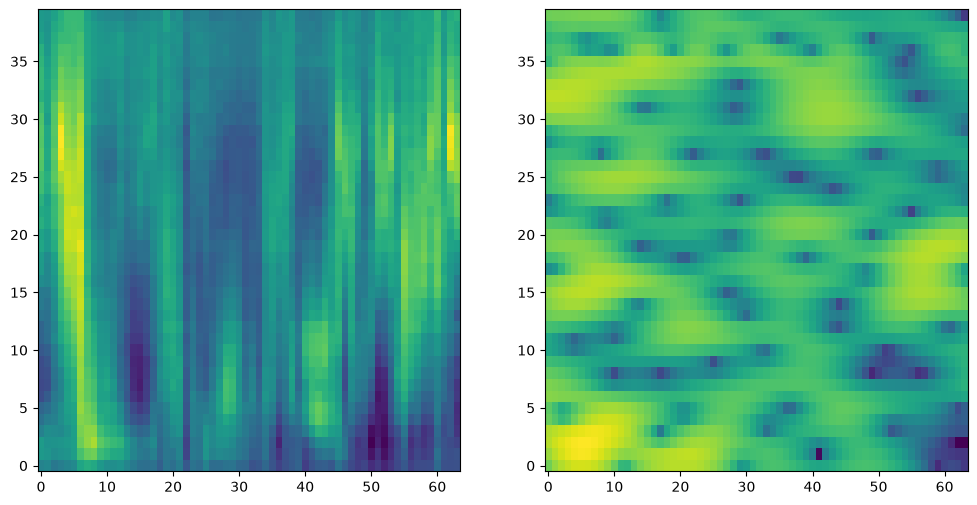

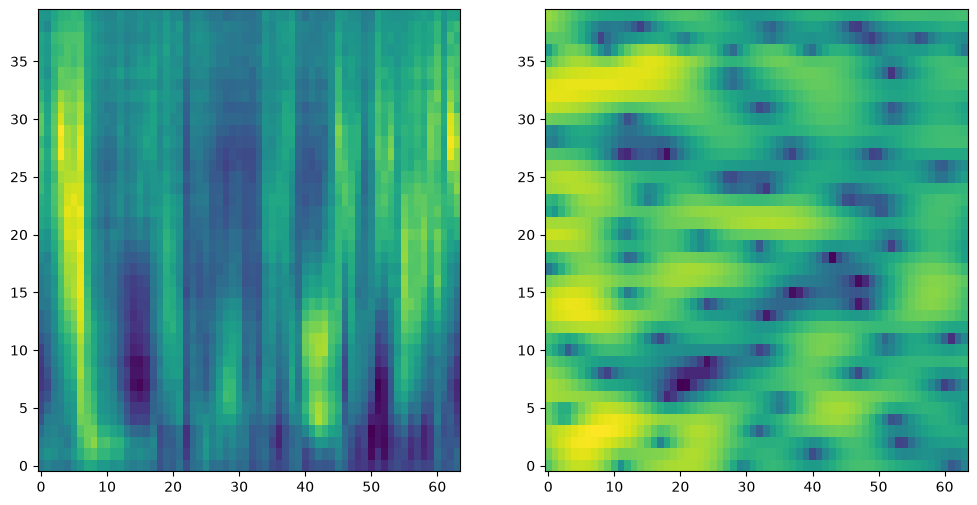

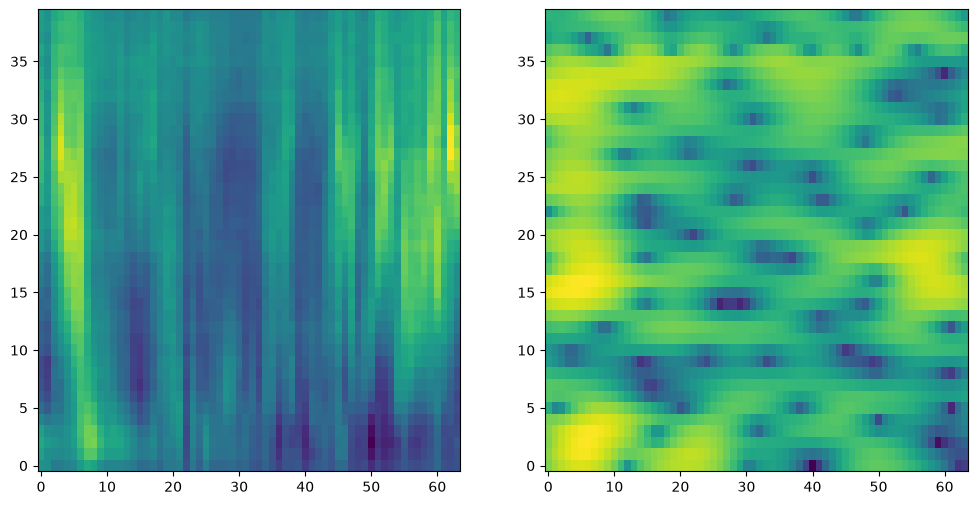

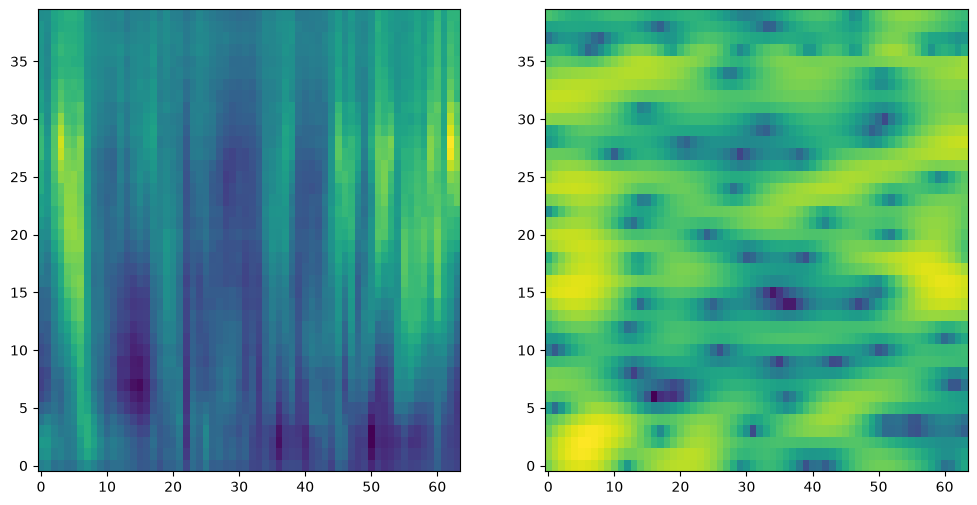

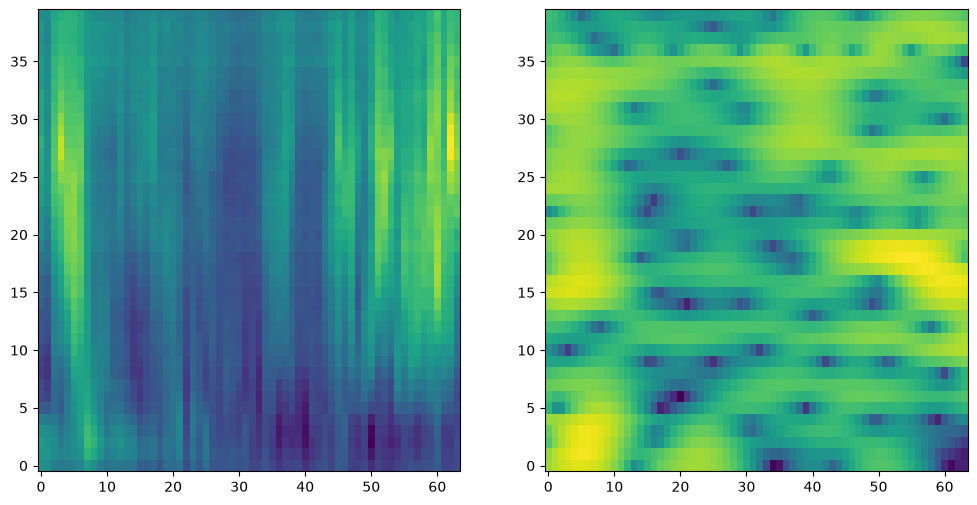

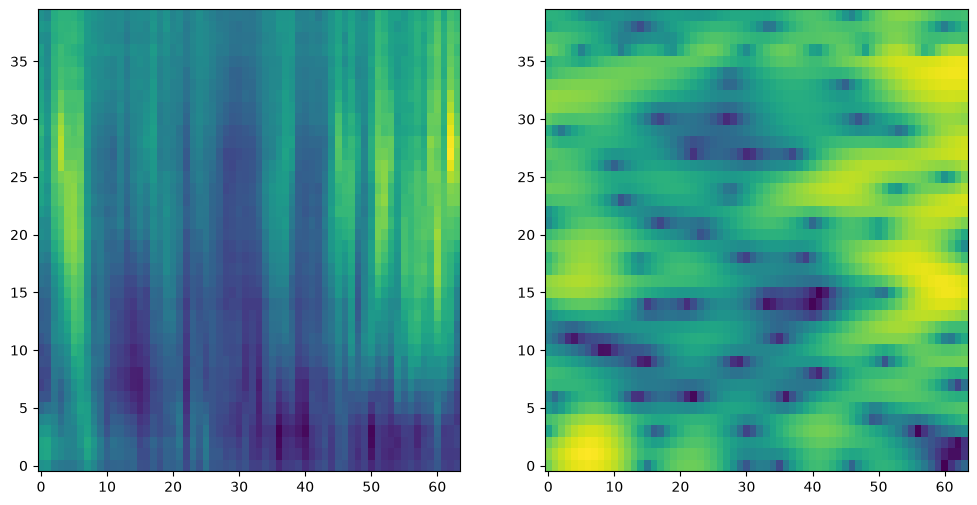

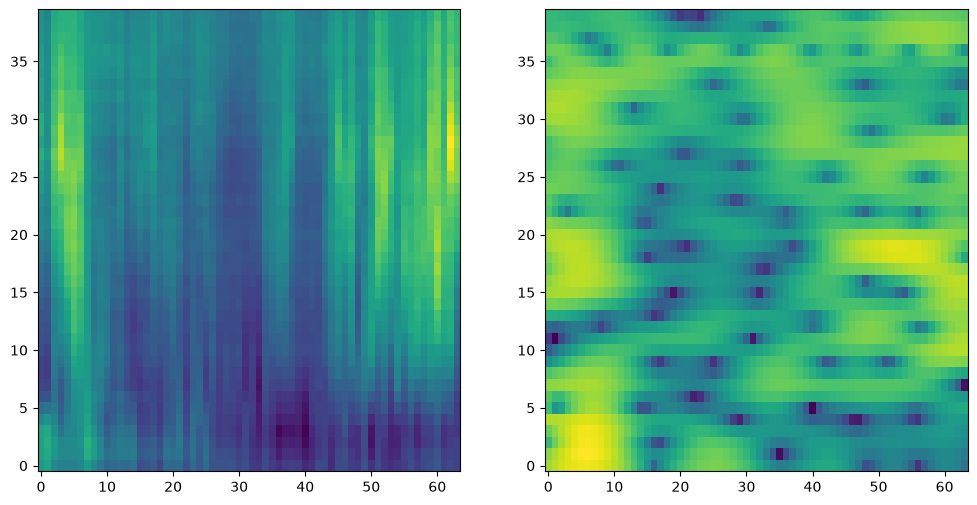

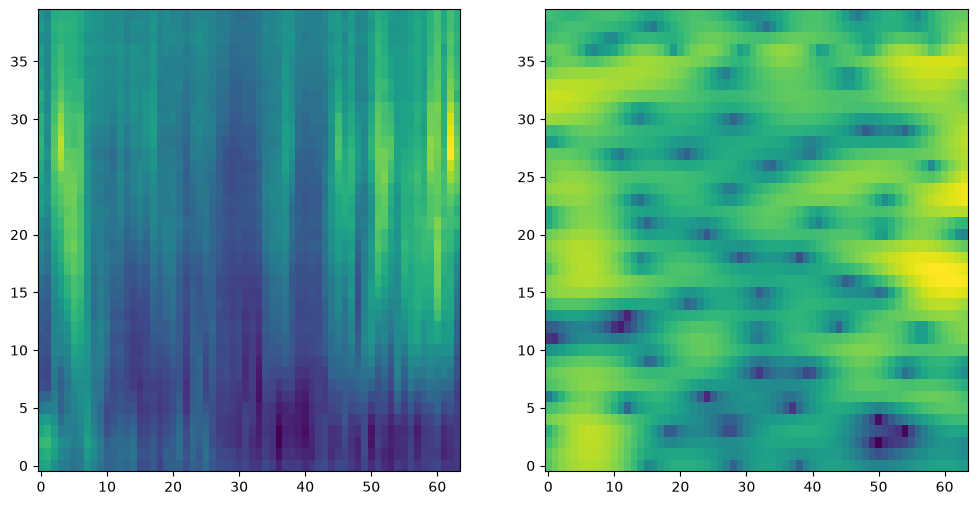

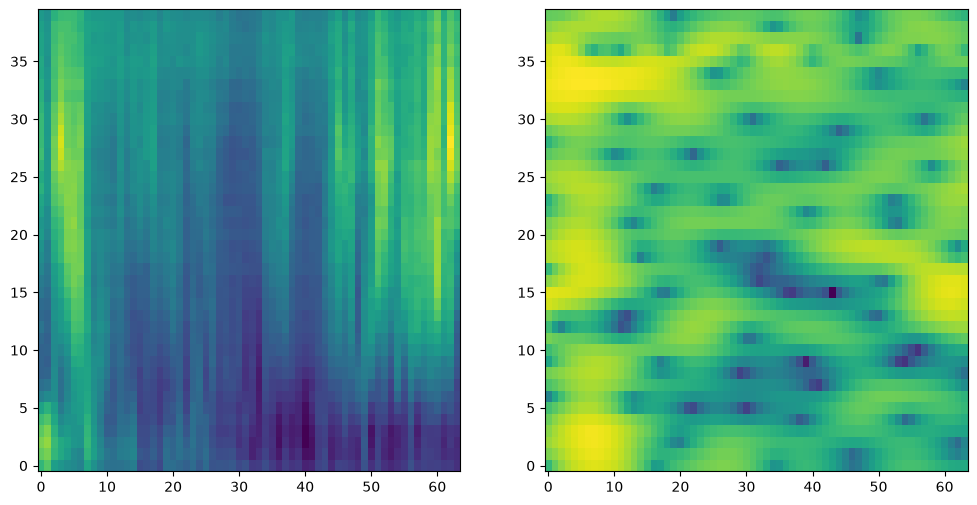

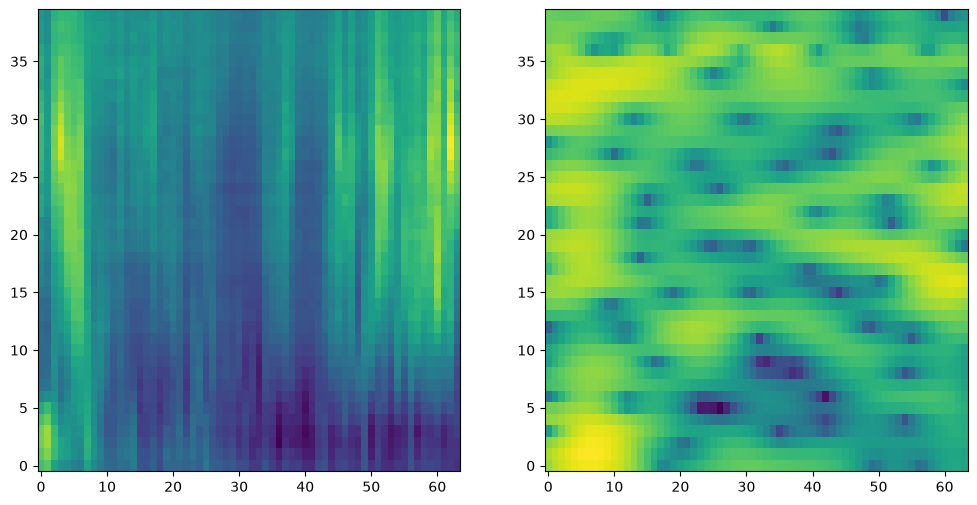

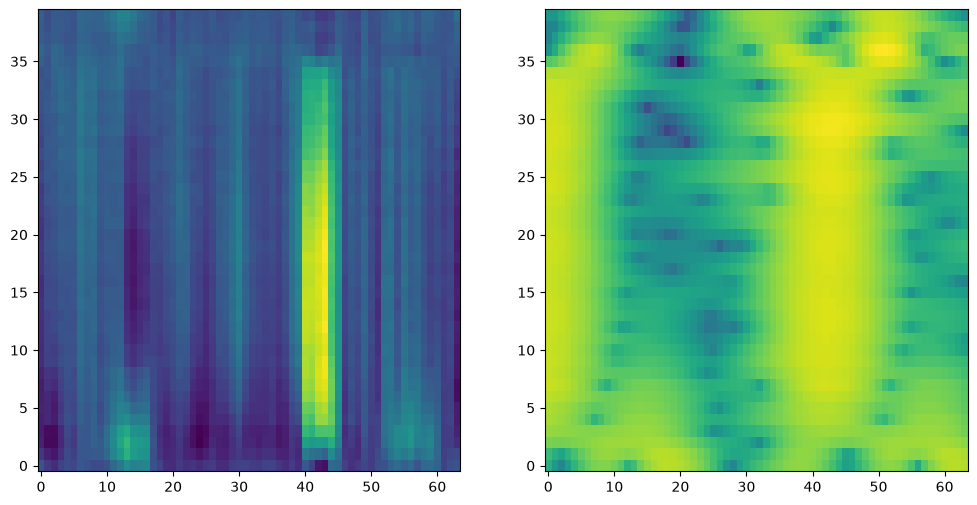

In [28]:
#plot test images
model.eval()
with torch.no_grad():
    batch = next(iter(trainloader))
    raw = batch[0].to(device)
    tfr = batch[1].to(device)
    with torch.autocast('cuda', dtype=torch.float16):   # matches how it was trained/evaluated
        output = tfr_encoder(raw).float()
    print(output.shape, tfr.shape, F.mse_loss(output, tfr).item())
    for sample, spectrogram in zip(output[0],tfr[0]): #each plot is channel
        fig, axs=plt.subplots(1,2,figsize=[12,6])
        axs[0].imshow(sample.cpu(),aspect='auto')
        axs[0].invert_yaxis()
        axs[1].imshow(spectrogram.cpu(),aspect='auto')
        axs[1].invert_yaxis()
        plt.show()

In [29]:
trainer.save_model('checkpoints/trainer/tfr.pt')

AttributeError: 'ModelTrainer' object has no attribute 'save_model'

# Resnet classifier

In [ ]:
from typing import Callable, Optional, Union
from torch import Tensor, flatten

def conv3x3(in_planes: int, out_planes: int, stride: int = 1, groups: int = 1, dilation: int = 1) -> nn.Conv2d:
    """3x3 convolution with padding"""
    return nn.Conv2d(
        in_planes,
        out_planes,
        kernel_size=3,
        stride=stride,
        padding=dilation,
        groups=groups,
        bias=False,
        dilation=dilation,
    )

def conv1x1(in_planes: int, out_planes: int, stride: int = 1) -> nn.Conv2d:
    """1x1 convolution"""
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)

class BasicBlock(nn.Module):
    expansion: int = 1

    def __init__(
        self,
        inplanes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
        groups: int = 1, #not sure where this comes up
        base_width: int = 64, #not sure where this comes up
        dilation: int = 1, #not sure where this comes up
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError("BasicBlock only supports groups=1 and base_width=64")
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = norm_layer(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = norm_layer(planes)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x: Tensor) -> Tensor:
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out

class Bottleneck(nn.Module):
    # Bottleneck in torchvision places the stride for downsampling at 3x3 convolution(self.conv2)
    # while original implementation places the stride at the first 1x1 convolution(self.conv1)
    # according to "Deep residual learning for image recognition" https://arxiv.org/abs/1512.03385.
    # This variant is also known as ResNet V1.5 and improves accuracy according to
    # https://ngc.nvidia.com/catalog/model-scripts/nvidia:resnet_50_v1_5_for_pytorch.

    expansion: int = 4

    def __init__(
        self,
        inplanes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
        groups: int = 1,
        base_width: int = 64,
        dilation: int = 1,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        width = int(planes * (base_width / 64.0)) * groups
        # Both self.conv2 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv1x1(inplanes, width)
        self.bn1 = norm_layer(width)
        self.conv2 = conv3x3(width, width, stride, groups, dilation)
        self.bn2 = norm_layer(width)
        self.conv3 = conv1x1(width, planes * self.expansion)
        self.bn3 = norm_layer(planes * self.expansion)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x: Tensor) -> Tensor:
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out

class ResNet(nn.Module):
    def __init__(
        self,
        block: type[Union[BasicBlock, Bottleneck]],
        layers: list[int],
        num_classes: int = 1000,
        zero_init_residual: bool = False,
        groups: int = 1,
        width_per_group: int = 64,
        replace_stride_with_dilation: Optional[list[bool]] = None,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
        in_channels=20
    ) -> None:
        super().__init__()
        #_log_api_usage_once(self)
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 64
        self.dilation = 1
        if replace_stride_with_dilation is None:
            # each element in the tuple indicates if we should replace
            # the 2x2 stride with a dilated convolution instead
            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError(
                "replace_stride_with_dilation should be None "
                f"or a 3-element tuple, got {replace_stride_with_dilation}"
            )
        self.groups = groups
        self.base_width = width_per_group

        '''
        self.conv1 = nn.Conv2d(3, self.inplanes, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        '''
        self.conv1 = nn.Conv2d(in_channels, self.inplanes, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2, dilate=replace_stride_with_dilation[0])
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2, dilate=replace_stride_with_dilation[1])
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2, dilate=replace_stride_with_dilation[2])
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512 * block.expansion, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, Bottleneck) and m.bn3.weight is not None:
                    nn.init.constant_(m.bn3.weight, 0)  # type: ignore[arg-type]
                elif isinstance(m, BasicBlock) and m.bn2.weight is not None:
                    nn.init.constant_(m.bn2.weight, 0)  # type: ignore[arg-type]

    def _make_layer(
        self,
        block: type[Union[BasicBlock, Bottleneck]],
        planes: int,
        blocks: int,
        stride: int = 1,
        dilate: bool = False,
    ) -> nn.Sequential:
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(
            block(
                self.inplanes, planes, stride, downsample, self.groups, self.base_width, previous_dilation, norm_layer
            )
        )
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(
                block(
                    self.inplanes,
                    planes,
                    groups=self.groups,
                    base_width=self.base_width,
                    dilation=self.dilation,
                    norm_layer=norm_layer,
                )
            )

        return nn.Sequential(*layers)

    def _forward_impl(self, x: Tensor) -> Tensor:
        # See note [TorchScript super()]
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = flatten(x, 1)
        x = self.fc(x)

        return x

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)

In [ ]:
# use trainer class
paths = sorted('data/' + d for d in os.listdir('data'))
random.Random(0).shuffle(paths)
f_pool_len=3
test_paths = paths[:1]
n_val = max(1, round(0.15 * len(paths)))
val_paths = paths[1:1 + n_val]
train_paths = paths[1 + n_val:]
print(f"{len(train_paths)} train / {len(val_paths)} val / {len(test_paths)} test recordings")
print("test file:", test_paths[0])
ch = slice(0,21)                                   # CHANGED
eeg_train = VarLenSliceDataset(train_paths, pool=(f_pool_len, 1), channels=ch)
eeg_val   = VarLenSliceDataset(val_paths,   pool=(f_pool_len, 1), channels=ch)
eeg_test  = VarLenSliceDataset(test_paths,  pool=(f_pool_len, 1), channels=ch)

trainloader = DataLoader(eeg_train,
                        batch_sampler=VarLenBatchSampler(n_batches=2000, batch_size=64*2),
                        num_workers=0)
valloader  = DataLoader(eeg_val, batch_sampler=FixedWinBatchSampler(), num_workers=0)
testloader = DataLoader(eeg_test, batch_sampler=FixedWinBatchSampler(reps=16), num_workers=0)
model=ResNet(Bottleneck,layers=[2,2,2,2],num_classes=2)
print('nparams:', count_parameters(model))

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.95))
schedular = torch.optim.lr_scheduler.StepLR(optimizer, gamma=0.2, step_size=800)
#scaler = torch.amp.GradScaler('cuda')
loss_fn =nn.MSELoss()

trainer=ModelTrainer(model,trainloader,valloader,loss_fn,optimizer,'testloop',base=log_dir,max_epochs=100,iter_schedular=schedular)
trainer.train()